# CAPSTONE PROJECT - ANITA AIFESEHI

### Import Libraries

In [3]:
# Import Libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

### Data Loading and Cleaning

In [5]:
# Loading data

df = pd.read_csv(r"C:\Users\anita\OneDrive\Documents\BOOTCAMP_DATA_ANALYTICS\ocd_patient_dataset.csv")

In [6]:
# Checking top 5

df.head(5)

,Patient ID,Age,Gender,Ethnicity,Marital Status,Education Level,OCD Diagnosis Date,Duration of Symptoms (months),Previous Diagnoses,Family History of OCD,Obsession Type,Compulsion Type,Y-BOCS Score (Obsessions),Y-BOCS Score (Compulsions),Depression Diagnosis,Anxiety Diagnosis,Medications
0,1018,32,Female,African,Single,Some College,2016-07-15,203,MDD,No,Harm-related,Checking,17,10,Yes,Yes,SNRI
1,2406,69,Male,African,Divorced,Some College,2017-04-28,180,NaN,Yes,Harm-related,Washing,21,25,Yes,Yes,SSRI
2,1188,57,Male,Hispanic,Divorced,College Degree,2018-02-02,173,MDD,No,Contamination,Checking,3,4,No,No,Benzodiazepine
3,6200,27,Female,Hispanic,Married,College Degree,2014-08-25,126,PTSD,Yes,Symmetry,Washing,14,28,Yes,Yes,SSRI
4,5824,56,Female,Hispanic,Married,High School,2022-02-20,168,PTSD,Yes,Hoarding,Ordering,39,18,No,No,NaN


In [7]:
# Checking for missing values

df.isnull().sum()

Patient ID                         0
Age                                0
Gender                             0
Ethnicity                          0
Marital Status                     0
Education Level                    0
OCD Diagnosis Date                 0
Duration of Symptoms (months)      0
Previous Diagnoses               248
Family History of OCD              0
Obsession Type                     0
Compulsion Type                    0
Y-BOCS Score (Obsessions)          0
Y-BOCS Score (Compulsions)         0
Depression Diagnosis               0
Anxiety Diagnosis                  0
Medications                      386
dtype: int64

In [8]:
df = pd.read_csv(r"C:\Users\anita\OneDrive\Documents\BOOTCAMP_DATA_ANALYTICS\ocd_patient_dataset.csv",
                 keep_default_na=False)

print("Missing values:", df.isna().sum().sum())          # 0

print("\nPrevious Diagnoses:")
print(df['Previous Diagnoses'].value_counts())           # None = 248

print("\nMedications:")
print(df['Medications'].value_counts())                  # None = 386

Missing values: 0

Previous Diagnoses:
Previous Diagnoses
MDD               345
Panic Disorder    313
GAD               298
PTSD              296
None              248
Name: count, dtype: int64

Medications:
Medications
Benzodiazepine    386
None              386
SNRI              376
SSRI              352
Name: count, dtype: int64


In [9]:
# Checking for missing values confirmnation 

df.isnull().sum()

Patient ID                       0
Age                              0
Gender                           0
Ethnicity                        0
Marital Status                   0
Education Level                  0
OCD Diagnosis Date               0
Duration of Symptoms (months)    0
Previous Diagnoses               0
Family History of OCD            0
Obsession Type                   0
Compulsion Type                  0
Y-BOCS Score (Obsessions)        0
Y-BOCS Score (Compulsions)       0
Depression Diagnosis             0
Anxiety Diagnosis                0
Medications                      0
dtype: int64

### Handling Missing Values

**Result: no values are missing. All 1,500 records are kept.**

When the file was first loaded, pandas reported 634 missing values: 248 in Previous Diagnoses and 386 in Medications. Those cells are not empty. They contain the word "None". By default, `pd.read_csv` treats the text "None" as a missing value (NaN), so pandas flagged them by mistake.

The word "None" is a real answer:
- **Previous Diagnoses = None:** the patient has no previous diagnosis (248 patients).
- **Medications = None:** the patient is not on any medication (386 patients).
- 59 patients have neither.

**Fix:** the file was reloaded with `keep_default_na=False`, so "None" is read as text. The check `df.isna().sum().sum()` then returns **0**, which confirms that no values are missing.

**Decision:** no rows were removed and nothing needed filling. Removing these rows would have deleted 575 patients (38.3% of the data) who gave a valid answer.

In [11]:
# Checking Top 5 to confirm data

df.head()

,Patient ID,Age,Gender,Ethnicity,Marital Status,Education Level,OCD Diagnosis Date,Duration of Symptoms (months),Previous Diagnoses,Family History of OCD,Obsession Type,Compulsion Type,Y-BOCS Score (Obsessions),Y-BOCS Score (Compulsions),Depression Diagnosis,Anxiety Diagnosis,Medications
0,1018,32,Female,African,Single,Some College,2016-07-15,203,MDD,No,Harm-related,Checking,17,10,Yes,Yes,SNRI
1,2406,69,Male,African,Divorced,Some College,2017-04-28,180,None,Yes,Harm-related,Washing,21,25,Yes,Yes,SSRI
2,1188,57,Male,Hispanic,Divorced,College Degree,2018-02-02,173,MDD,No,Contamination,Checking,3,4,No,No,Benzodiazepine
3,6200,27,Female,Hispanic,Married,College Degree,2014-08-25,126,PTSD,Yes,Symmetry,Washing,14,28,Yes,Yes,SSRI
4,5824,56,Female,Hispanic,Married,High School,2022-02-20,168,PTSD,Yes,Hoarding,Ordering,39,18,No,No,None


In [12]:
# Checking for data informations

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 17 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Patient ID                     1500 non-null   int64 
 1   Age                            1500 non-null   int64 
 2   Gender                         1500 non-null   object
 3   Ethnicity                      1500 non-null   object
 4   Marital Status                 1500 non-null   object
 5   Education Level                1500 non-null   object
 6   OCD Diagnosis Date             1500 non-null   object
 7   Duration of Symptoms (months)  1500 non-null   int64 
 8   Previous Diagnoses             1500 non-null   object
 9   Family History of OCD          1500 non-null   object
 10  Obsession Type                 1500 non-null   object
 11  Compulsion Type                1500 non-null   object
 12  Y-BOCS Score (Obsessions)      1500 non-null   int64 
 13  Y-B

In [13]:
# Checking for duplicate data values

df.duplicated().sum()

0

In [14]:
# Checking for statistics of the data

df.describe()

,Patient ID,Age,Duration of Symptoms (months),Y-BOCS Score (Obsessions),Y-BOCS Score (Compulsions)
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.00000
mean,5541.254000,46.781333,121.745333,20.048000,19.62600
std,2562.389469,16.830321,67.404610,11.823884,11.78287
min,1017.000000,18.000000,6.000000,0.000000,0.00000
25%,3338.000000,32.000000,64.000000,10.000000,9.00000
50%,5539.500000,47.000000,121.000000,20.000000,20.00000
75%,7745.500000,61.000000,178.000000,31.000000,29.00000
max,9995.000000,75.000000,240.000000,40.000000,40.00000


In [15]:
# Checking the columns data types

df.dtypes

Patient ID                        int64
Age                               int64
Gender                           object
Ethnicity                        object
Marital Status                   object
Education Level                  object
OCD Diagnosis Date               object
Duration of Symptoms (months)     int64
Previous Diagnoses               object
Family History of OCD            object
Obsession Type                   object
Compulsion Type                  object
Y-BOCS Score (Obsessions)         int64
Y-BOCS Score (Compulsions)        int64
Depression Diagnosis             object
Anxiety Diagnosis                object
Medications                      object
dtype: object

In [16]:
# Checking the number of rows and column of the data

df.shape

(1500, 17)

### Exploratory Data Analysis (EDA)

In [18]:
# Obsession scores by depression diagnosis

df.groupby('Depression Diagnosis').agg(
    Records=('Y-BOCS Score (Obsessions)', 'size'),
    Average_Obsession_Score=('Y-BOCS Score (Obsessions)', 'mean')
).round(2)

,Records,Average_Obsession_Score
Depression Diagnosis,,
No,728,20.05
Yes,772,20.04


Records with a depression diagnosis (772 records) had an average obsession score of 20.04, compared with 20.05 for records without one (728 records). The difference is 0.01 points, so the two groups are essentially identical, and it is not statistically significant (p = 0.989). This does not prove that depression causes higher or lower obsession scores.

In [20]:
# Obession scores by Obession type

df.groupby('Obsession Type').agg(
    Records=('Y-BOCS Score (Obsessions)', 'size'),
    Average_Obsession_Score=('Y-BOCS Score (Obsessions)', 'mean')
).round(2).sort_values('Average_Obsession_Score', ascending=False)

,Records,Average_Obsession_Score
Obsession Type,,
Hoarding,278,21.01
Harm-related,333,20.65
Contamination,306,19.67
Symmetry,280,19.67
Religious,303,19.23


Harm-related was the most common obsession type (333 records), while Hoarding was the least common (278 records). However, Hoarding had the highest average obsession score (21.01) and Religious had the lowest (19.23), a difference of 1.78 points on a 0-40 scale. The most common type is therefore not the type with the highest average score.

These are descriptive differences between groups. The gap between the five types is not statistically significant (p = 0.314), and they do not establish that obsession type causes a higher or lower score.

In [22]:
# Complusion scores by Anxiety diagnosis

df.groupby('Anxiety Diagnosis').agg(
    Records=('Y-BOCS Score (Compulsions)', 'size'),
    Average_Compulsion_Score=('Y-BOCS Score (Compulsions)', 'mean')
).round(2)

,Records,Average_Compulsion_Score
Anxiety Diagnosis,,
No,749,19.93
Yes,751,19.33


Those with an anxiety diagnosis had an average compulsion score of 19.33, compared with 19.93 for those without. The observed difference was 0.73 points. This descriptive comparison does not establish causation or show whether the difference is clinically meaningful.

                                 Age  Duration of Symptoms (months)  \
Age                            1.000                         -0.002   
Duration of Symptoms (months) -0.002                          1.000   
Y-BOCS Score (Obsessions)     -0.003                          0.008   
Y-BOCS Score (Compulsions)     0.014                          0.040   

                               Y-BOCS Score (Obsessions)  \
Age                                               -0.003   
Duration of Symptoms (months)                      0.008   
Y-BOCS Score (Obsessions)                          1.000   
Y-BOCS Score (Compulsions)                         0.031   

                               Y-BOCS Score (Compulsions)  
Age                                                 0.014  
Duration of Symptoms (months)                       0.040  
Y-BOCS Score (Obsessions)                           0.031  
Y-BOCS Score (Compulsions)                          1.000  


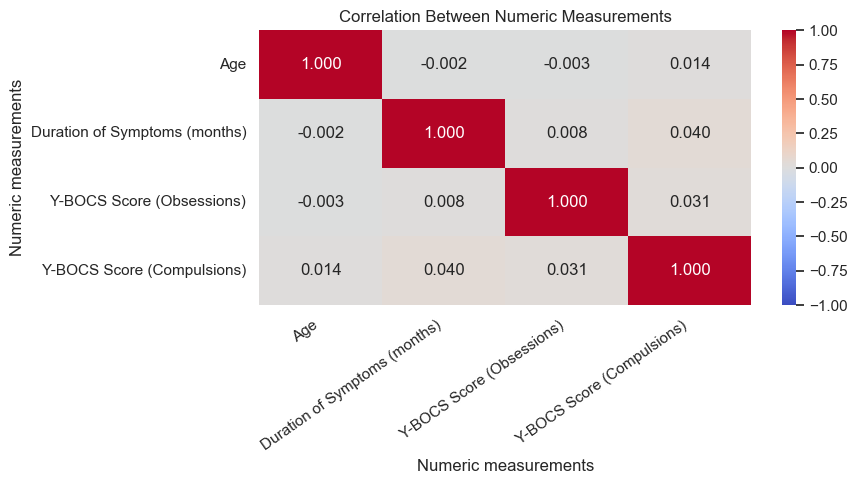

In [24]:
numeric_columns = [
    'Age',
    'Duration of Symptoms (months)',
    'Y-BOCS Score (Obsessions)',
    'Y-BOCS Score (Compulsions)'
]

correlation = df[numeric_columns].corr()
print(correlation.round(3))

plt.figure(figsize=(9, 5))

sns.heatmap(
    correlation,
    annot=True,
    fmt='.3f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Between Numeric Measurements')
plt.xlabel('Numeric measurements')
plt.ylabel('Numeric measurements')

plt.xticks(rotation=35, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

All correlations between age, symptom duration, obsession score and compulsion score are very close to zero, ranging from -0.003 to 0.040. The strongest is between symptom duration and compulsion score (0.040), followed by obsession score and compulsion score (0.031). Even the strongest relationship explains only about 0.16% of the variation in compulsion scores.

With 1,500 records, a correlation would need to be larger than about 0.051 (positive or negative) to stand out from chance, and none of the six pairs reaches this (all p-values are above 0.12). Longer symptom duration, older age, or a higher obsession score therefore does not go with a higher compulsion score in this dataset. Obsession and compulsion scores also appear to vary independently of each other. Correlation shows how closely two measures move together, not whether one causes the other.

Lower bound: -107.0
Upper bound: 349.0
Number of outliers: 0


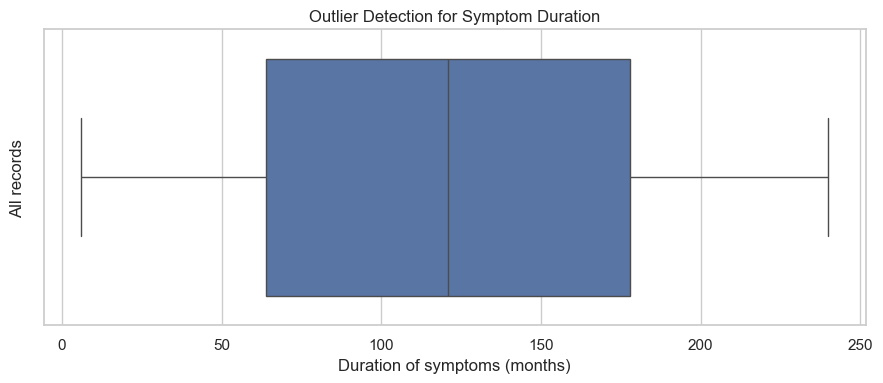

In [26]:
# Outlier detection: symptom duration

column = 'Duration of Symptoms (months)'

Q1 = df[column].quantile(0.25)
Q3 = df[column].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df[column] < lower_bound) |
    (df[column] > upper_bound)
]

print('Lower bound:', lower_bound)
print('Upper bound:', upper_bound)
print('Number of outliers:', len(outliers))

plt.figure(figsize=(9, 4))
sns.boxplot(x=df[column])

plt.title('Outlier Detection for Symptom Duration')
plt.xlabel('Duration of symptoms (months)')
plt.ylabel('All records')

plt.tight_layout()
plt.show()

The IQR method flags a value as an outlier if it falls below -107 months or above 349 months. No records fall outside these limits, so there are 0 outliers in symptom duration.

The box plot supports this. Durations range from 6 to 240 months (0.5 to 20 years), with a median of 121 months (about 10 years) and a middle 50% of records between 64 and 178 months. The whiskers reach the minimum and maximum values, and there are no points beyond them. The median sits near the centre of the box, so the values are spread fairly evenly across the range.

Nothing was removed or changed. Because the lower limit is negative (-107), it can never be reached (a duration cannot be below 0), so the useful check is the upper limit: the longest recorded duration (240 months) is well below 349 months.

### VISUALISATION 

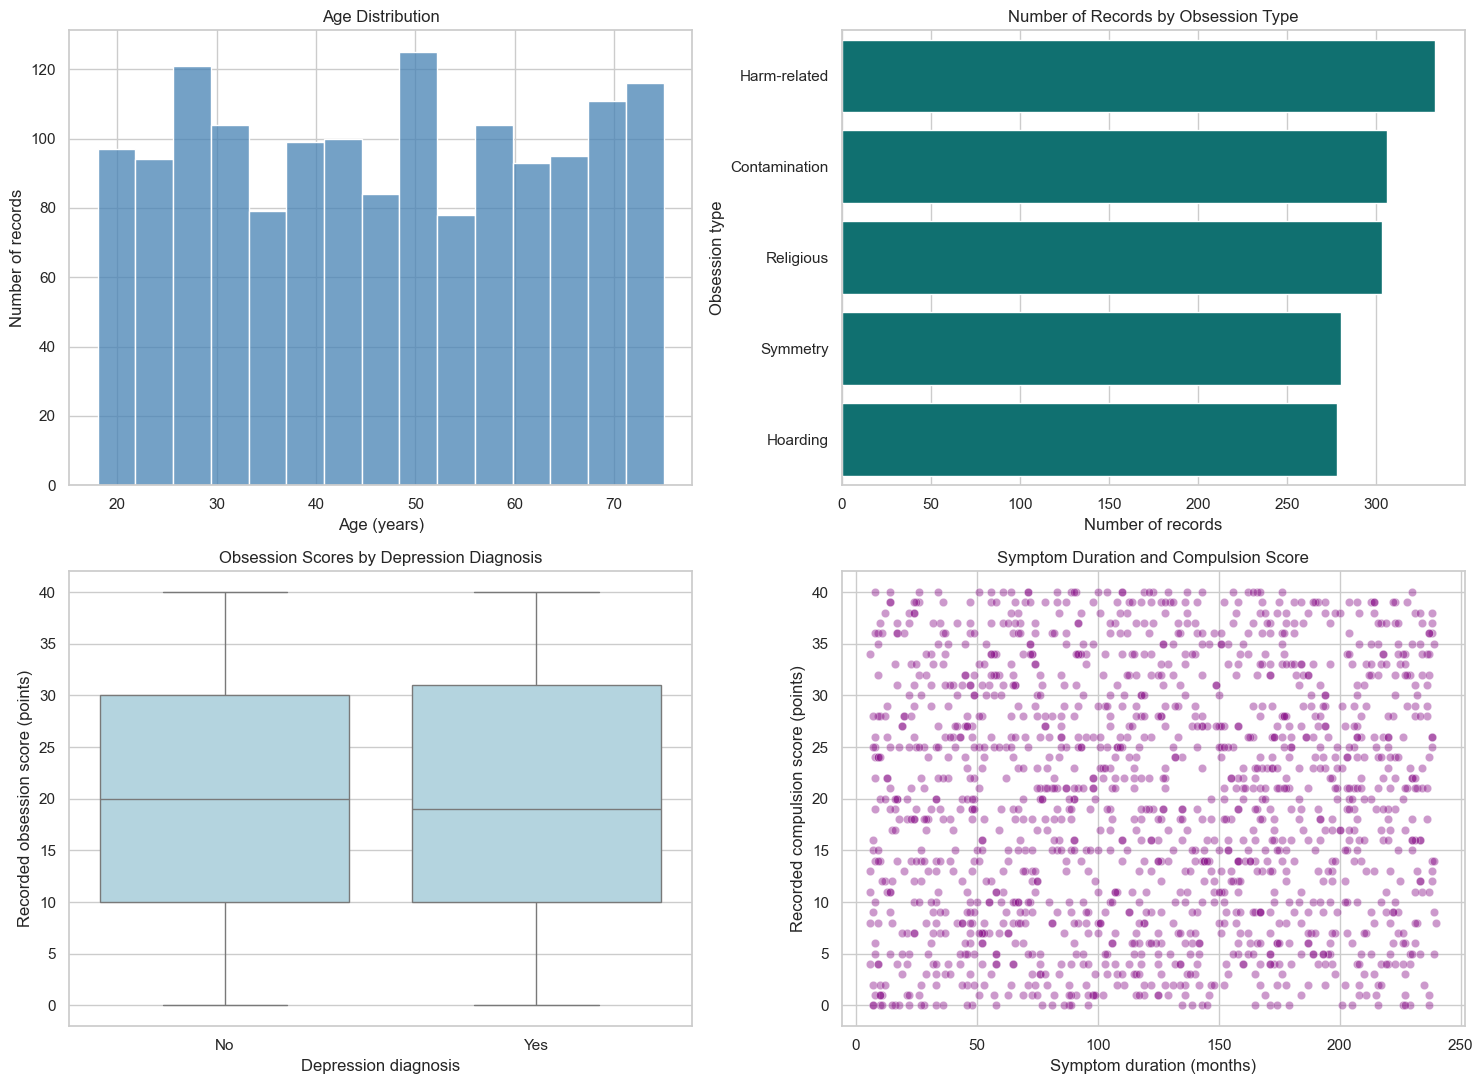

In [41]:
# Create a grid with 2 rows and 2 columns
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Chart 1: Distribution of ages
sns.histplot(
    data=df,
    x='Age',
    bins=15,
    color='steelblue',
    ax=axes[0, 0]
)
axes[0, 0].set_title('Age Distribution')
axes[0, 0].set_xlabel('Age (years)')
axes[0, 0].set_ylabel('Number of records')

# Chart 2: Number of records by obsession type
sns.countplot(
    data=df,
    y='Obsession Type',
    order=df['Obsession Type'].value_counts().index,
    color='teal',
    ax=axes[0, 1]
)
axes[0, 1].set_title('Number of Records by Obsession Type')
axes[0, 1].set_xlabel('Number of records')
axes[0, 1].set_ylabel('Obsession type')

# Chart 3: Obsession scores by depression diagnosis
sns.boxplot(
    data=df,
    x='Depression Diagnosis',
    y='Y-BOCS Score (Obsessions)',
    order=['No', 'Yes'],
    color='lightblue',
    ax=axes[1, 0]
)
axes[1, 0].set_title('Obsession Scores by Depression Diagnosis')
axes[1, 0].set_xlabel('Depression diagnosis')
axes[1, 0].set_ylabel('Recorded obsession score (points)')

# Chart 4: Symptom duration and compulsion score
sns.scatterplot(
    data=df,
    x='Duration of Symptoms (months)',
    y='Y-BOCS Score (Compulsions)',
    color='purple',
    alpha=0.4,
    ax=axes[1, 1]
)
axes[1, 1].set_title('Symptom Duration and Compulsion Score')
axes[1, 1].set_xlabel('Symptom duration (months)')
axes[1, 1].set_ylabel('Recorded compulsion score (points)')

plt.tight_layout()
plt.show()

**Age distribution.** Ages range from 18 to 75 (mean 46.78, median 47), and the bars are spread across the whole range with no clear peak. Bar heights run from 78 to 125 records, but the two shortest bars (79 and 78 records) each cover only three whole-number ages, while the others cover four. This is an effect of how the bins are cut, not a real dip in the data. Against an even spread by age, the counts are consistent (p = 0.281).

**Records by obsession type.** Harm-related was the most common obsession type (333 records), followed by Contamination (306), Religious (303) and Symmetry (280). Hoarding was the least common (278). The gap between the most and least common is 55 records, and the last two are almost equal.

**Obsession scores by depression diagnosis.** The two boxes are almost identical. Records without a depression diagnosis have a median of 20 (middle half between 10 and 30), and records with one have a median of 19 (middle half between 10 and 31). Both groups cover the full 0-40 range, and their averages are 20.05 and 20.04. Depression diagnosis does not separate the obsession scores.

**Symptom duration and compulsion score.** The points fill the whole chart with no upward or downward pattern. Longer symptom duration does not go with higher compulsion scores (correlation 0.040, p = 0.122), which is consistent with the correlation analysis.

Overall, the charts show evenly spread ages, similar group sizes, overlapping score distributions and no visible relationship between duration and compulsion score. These are descriptive patterns in the 1,500 records and should not be generalised to all people with OCD.

## Business Story: Understanding Patterns in OCD Records

### Context
A mental health service manager wants to understand the mix of records and their recorded symptom scores to inform service reporting. This analysis examines all 1,500 health records (17 columns). No values are missing: the entries "None" in Previous Diagnoses (248 records) and Medications (386 records) are valid answers meaning no previous diagnosis and no medication, and 59 records have neither. No rows were removed. Obsession and compulsion scores are each recorded on a 0-40 scale, and the average scores are 20.05 for obsessions and 19.63 for compulsions.

### Finding
Harm-related was the most common obsession type, appearing in 333 records, and Hoarding was the least common, with 278. However, Hoarding had the highest average obsession score at 21.01, while Religious had the lowest at 19.23, a gap of 1.78 points on a 0-40 scale. This shows that the most common category is not necessarily the category with the highest average score, and that the smallest group scored highest. The gap between the five obsession types is not statistically significant (p = 0.314).

### Deeper Finding
Average obsession scores were almost identical for records with and without a depression diagnosis: 20.04 (772 records) and 20.05 (728 records), respectively, a difference of 0.01 points (p = 0.989). Their score distributions also overlapped substantially, with medians of 19 and 20.

Records with an anxiety diagnosis averaged 19.33 on compulsions (751 records), compared with 19.93 without (749 records), a 0.60-point gap (p = 0.326).

Symptom duration had a very weak correlation with compulsion score (0.040, p = 0.122). Longer recorded symptom duration did not show a clear linear association with higher compulsion scores. All correlations between age, symptom duration, obsession score and compulsion score ranged from -0.003 to 0.040, and none is large enough to stand out from chance (a correlation would need to exceed about 0.051). Obsession and compulsion scores were almost unrelated (0.031, p = 0.236).

Compulsion type showed the largest difference in the dataset. Praying had the highest average compulsion score (20.73, 286 records) and Checking the lowest (17.92, 292 records), a gap of about 2.8 points, followed by Ordering (20.23), Counting (19.66) and Washing (19.63). The overall test across the five types just misses the usual 5% cut-off (p = 0.051), while the Praying versus Checking comparison is significant after allowing for all type comparisons (p = 0.033). The gap is small in size (about a quarter of one standard deviation), and it is one of several comparisons made, so it should be treated as a lead to re-check on new data, not a confirmed finding.

Together, these findings show why record counts, group averages, and score distributions should be considered together.

### Recommendation

1. **Assess obsession and compulsion symptoms separately during diagnosis and follow-up.** Since obsession and compulsion scores are almost unrelated in this dataset (correlation 0.031), a patient's obsession score should not be used to assume their compulsion score.

2. **Do not tailor treatment plans by obsession type based on this dataset.** Average obsession scores differed by only 1.78 points across the five types, and the difference was not statistically significant. Depression and anxiety diagnoses also made almost no difference to scores (0.01 and 0.60 points).

3. **Follow up the Checking result before acting on it.** Checking had the lowest average compulsion score (17.92 against 20.73 for Praying). Because this is the only borderline result (p = 0.051), it should be re-tested on independent or more recent data before it influences services.

4. **Use repeated Y-BOCS assessments to monitor treatment progress.** Because age and symptom duration show almost no relationship with severity in this dataset (correlations of 0.014 and 0.040 with compulsion score, -0.003 and 0.008 with obsession score), decisions should rely on the patient's current obsession and compulsion scores and how those scores change over time.

5. **Validate the data before using it for reporting.** Only 1,393 of the 1,500 Patient IDs are unique, and repeated IDs belong to different people. Also, each Y-BOCS score runs to 40 (717 obsession scores and 722 compulsion scores are above 20), while the standard scale scores obsessions and compulsions each out of 20. The data source should confirm both points.

This analysis supports further investigation and better reporting; it does not establish which treatments work or how staffing should change.

### Cause - What might explain the finding?
A possible explanation is that the differences between groups reflect random variation in data where the recorded measures are not related to each other, rather than a real effect of symptom type, diagnosis, age or symptom duration. This is a possible reason, not a proven one. The 1,500 records show patterns that point in this direction:

- **Scores are spread close to evenly across their full range.** Obsession scores, compulsion scores, age and symptom duration each stay close to an even spread (tests p = 0.50, 0.14, 0.89 and 0.23). Their means (20.05, 19.63, 46.78, 121.75) and standard deviations (11.82, 11.78, 16.83, 67.40) sit close to what an even spread predicts (means 20.0, 20.0, 46.5, 123.0; standard deviations 11.83, 11.83, 16.74, 67.84).
- **Categories are split almost exactly evenly.** For example, 753 male and 747 female; 751 with anxiety and 749 without; 760 with a family history and 740 without; and 386, 386, 376 and 352 across the four medication categories (None, Benzodiazepine, SNRI, SSRI).
- **Variables are unrelated.** All correlations are close to zero (-0.003 to 0.040), and with 1,500 records a correlation would need to exceed about 0.051 to stand out from chance. None does.
- **Chance can produce gaps of this size.** Each obsession type has 278-333 records and each compulsion type 285-321, so each group average is uncertain by about 0.65 to 0.71 points (standard error). Across obsession types, the largest gap (1.78 points) is well within what shuffling the labels produces (p = 0.352). Ten comparisons were run in this analysis (two symptom-type tests, depression, anxiety and six correlations), so even with no real effects there is about a 40% chance that at least one would fall below p = 0.05. A borderline result such as p = 0.051 is therefore not surprising.
- **Data quality flags.** Only 1,393 of the 1,500 Patient IDs are unique. 99 IDs are used more than once (206 records), and in 97 of them the two records have different ages, so they are different people. The 107 repeated records are close to the roughly 119 expected if IDs were assigned at random from the range 1,017 to 9,995. Also, each Y-BOCS score runs to 40 (717 obsession scores and 722 compulsion scores are above 20), while the standard scale scores obsessions and compulsions each out of 20.

Together, these patterns suggest the dataset may be randomly generated rather than collected from real patients. This should be confirmed with the data source. If the data is real, other possible reasons, such as differences in how or where patients were assessed, cannot be tested because the dataset has no information on treatment, clinician or setting.

### Effect - What did we observe?
**Obsession type.** Hoarding had an average obsession score of 21.01, compared with 19.23 for Religious obsessions, a difference of 1.78 points. Compared on their own, this gap gives p = 0.073. Across all five obsession types it is not significant (ANOVA p = 0.314; the smallest p across all type pairs is 0.366; a shuffle test gives p = 0.352).

**Compulsion type.** Praying had an average compulsion score of 20.73, compared with 17.92 for Checking, a difference of about 2.8 points. Compared on their own, this gap gives p = 0.004, but it is the largest gap among five groups, so it was picked because it is the biggest, and that p-value overstates the evidence. Once all five types are considered, the result is borderline: the overall test gives p = 0.051, the Praying versus Checking comparison gives p = 0.033, and a shuffle test gives p = 0.028. The gap is small in size, about a quarter of one standard deviation (0.24).

**Diagnoses and correlations.** Records with a depression diagnosis averaged 20.04 on obsessions, compared with 20.05 without (p = 0.989). Records with an anxiety diagnosis averaged 19.33 on compulsions, compared with 19.93 without, a 0.60-point gap (p = 0.326). No correlation between age, symptom duration and the two scores exceeded 0.040 (p = 0.122).

These are observed differences between groups, not measured causal effects.

### Business Impact - Why does this matter?
A single overall average could hide differences between symptom groups, but here the differences are small enough that acting on them would mean acting on likely random variation. For example, Hoarding has the highest average obsession score (21.01), but it is the smallest group (278 records, 18.5% of the total) and its lead over Religious is 1.78 points, under 5% of the 40-point scale. A service built around it would rest on a gap that is not statistically significant (p = 0.314). Checking is the one result worth following up (17.92, against 20.73 for Praying), but with p = 0.051 it should be re-tested on new data before it influences services. Reporting group counts, averages and distributions together makes this visible and helps managers identify questions for further investigation.

The next step is to validate the data: confirm its source, why Patient IDs repeat across different people, and the score scale. Then collect information on service demand, costs, and follow-up outcomes. Financial savings, staffing needs, and improvements in care cannot be estimated from this dataset alone.

Data Source: https://www.kaggle.com/datasets/ohinhaque/ocd-patient-dataset-demographics-and-clinical-data/data